В цьому ноутбуці відбуваєтся перевірка одного активу на рандомних відрізках часу. Метою є перевірка чи отримані загальні результати релевантні для різних режимів ринку

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np

import random
import yaml

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
STOCK = 'ETH'
SEQUENCE_LENGTH = 365 * 4
N_PERIODS = 10

# stocks

In [4]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,XRP,BNB,ADA,SOL,DOGE,DOT,LTC,LINK,...,XVG,BCN,NXT,PPC,NMC,DGB,SC,QTUM,ICX,LSK
Date,,,,,,,,,,,,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.058550,NaN,...,NaN,NaN,NaN,1.540270,1.264560,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.685230,NaN,...,NaN,NaN,NaN,1.685280,1.229760,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.327770,NaN,...,NaN,NaN,NaN,1.216330,1.104190,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.286440,NaN,...,NaN,NaN,NaN,1.641050,1.194410,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.245920,NaN,...,NaN,NaN,NaN,1.488790,1.110980,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,1.334452,740.823608,0.223782,106.422340,0.081809,1.149771,61.531612,12.320927,...,0.002583,0.000059,NaN,0.446449,1.317299,0.003360,0.000820,0.877745,0.009176,0.197685
2026-10-21,84011.968750,2470.766113,1.363619,745.868347,0.224979,106.793655,0.081867,1.141323,61.454342,12.484719,...,0.002605,0.000037,NaN,0.343409,1.176803,0.003399,0.000850,0.889200,0.008703,0.196787
2026-10-22,81311.890625,2386.189209,1.307656,730.476624,0.212025,103.542320,0.078676,1.111869,58.756485,11.943166,...,0.002455,0.000029,NaN,0.342047,1.535211,0.003527,0.000893,0.852186,0.009433,0.183983


In [5]:
asset_prices = df_stocks[STOCK].dropna()

periods = []
for i in range(N_PERIODS):
    start = random.randint(0, len(asset_prices) - SEQUENCE_LENGTH)
    period_prices = asset_prices.iloc[start:start + SEQUENCE_LENGTH]
    periods.append({
        "period_id": i + 1,
        "start": period_prices.index.min(),
        "end": period_prices.index.max(),
        "prices": period_prices,
    })

In [6]:
pd.DataFrame(
    [{"period": p["period_id"], "start": p["start"], "end": p["end"], "days": len(p["prices"])} for p in periods]
 )

,period,start,end,days
0,1,2021-06-12,2025-06-10,1460
1,2,2020-06-18,2024-06-16,1460
2,3,2021-03-28,2025-03-26,1460
3,4,2019-01-09,2023-01-07,1460
4,5,2019-01-06,2023-01-04,1460
5,6,2018-06-22,2022-06-20,1460
6,7,2021-10-21,2025-10-19,1460
7,8,2021-05-06,2025-05-04,1460
8,9,2018-09-17,2022-09-15,1460
9,10,2021-12-22,2025-12-20,1460


In [7]:
strategy = {
    "buy_amount": 10,
}

22:49:43 - cmdstanpy - INFO - Chain [1] start processing
22:49:43 - cmdstanpy - INFO - Chain [1] done processing


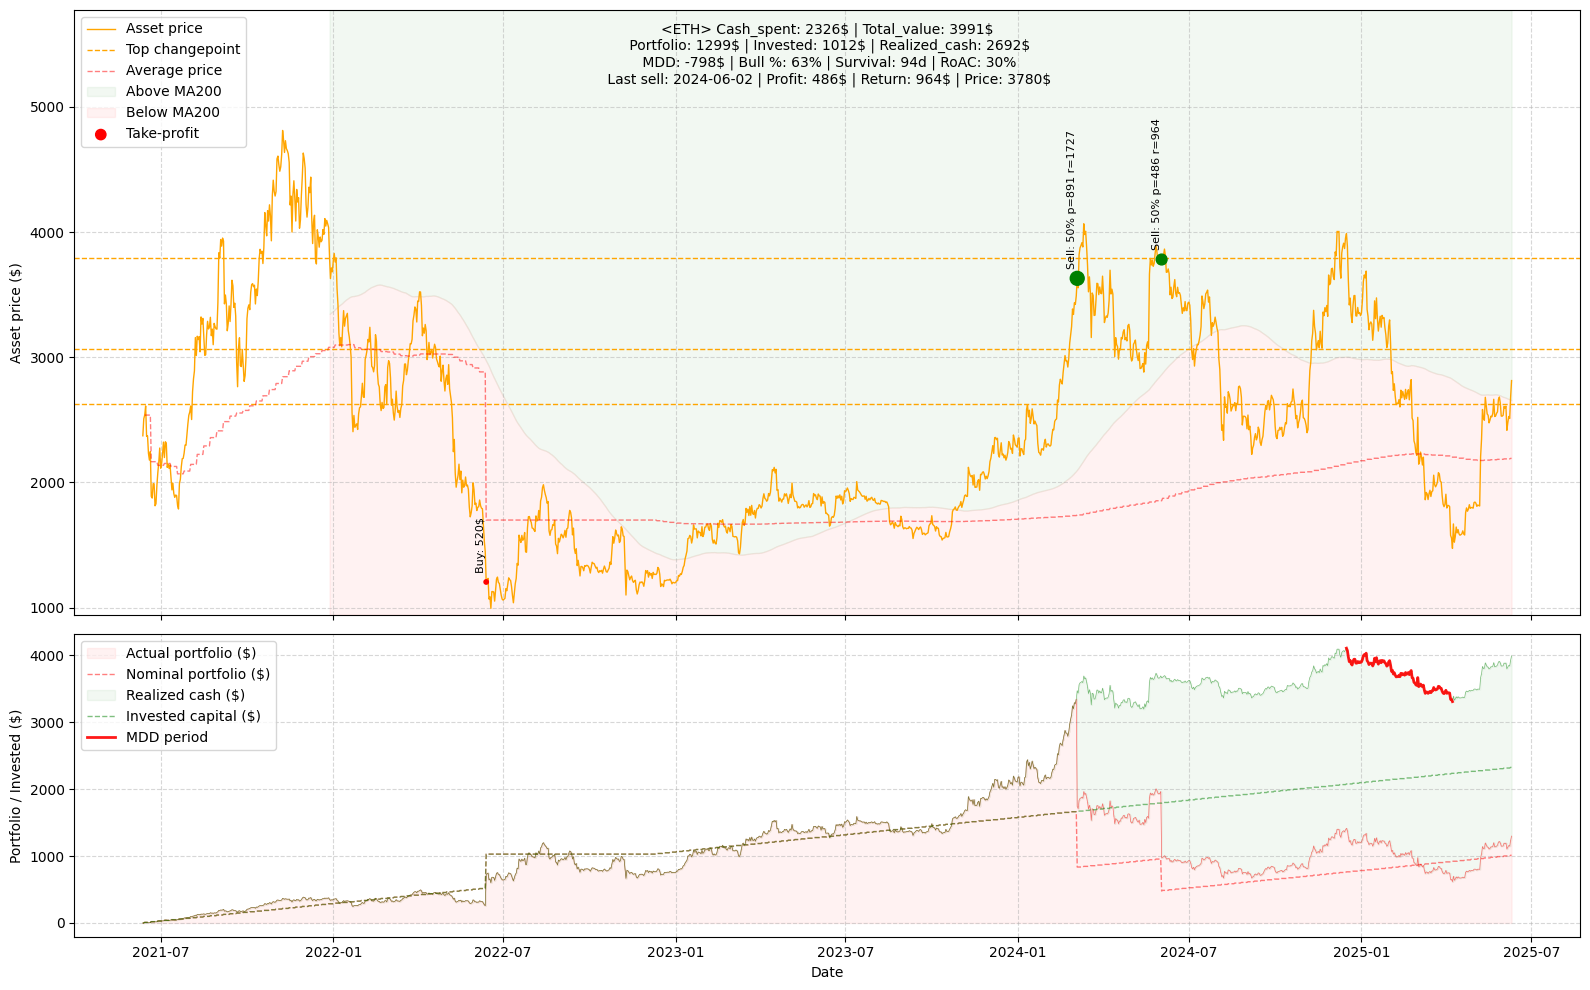

22:49:43 - cmdstanpy - INFO - Chain [1] start processing
22:49:44 - cmdstanpy - INFO - Chain [1] done processing


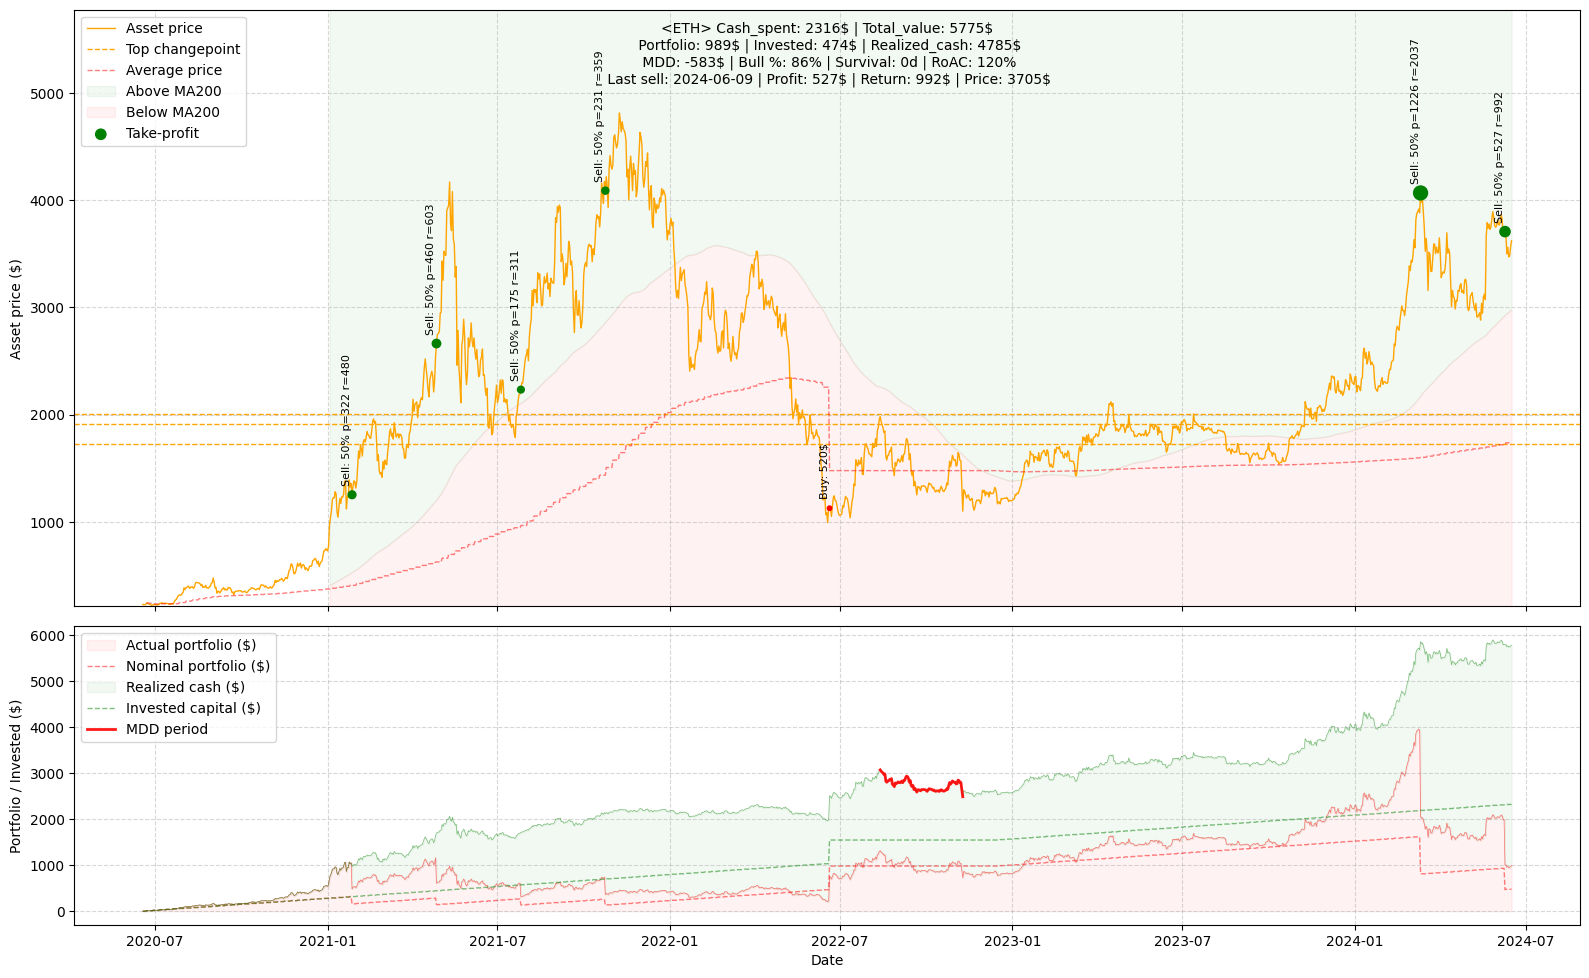

22:49:44 - cmdstanpy - INFO - Chain [1] start processing
22:49:44 - cmdstanpy - INFO - Chain [1] done processing


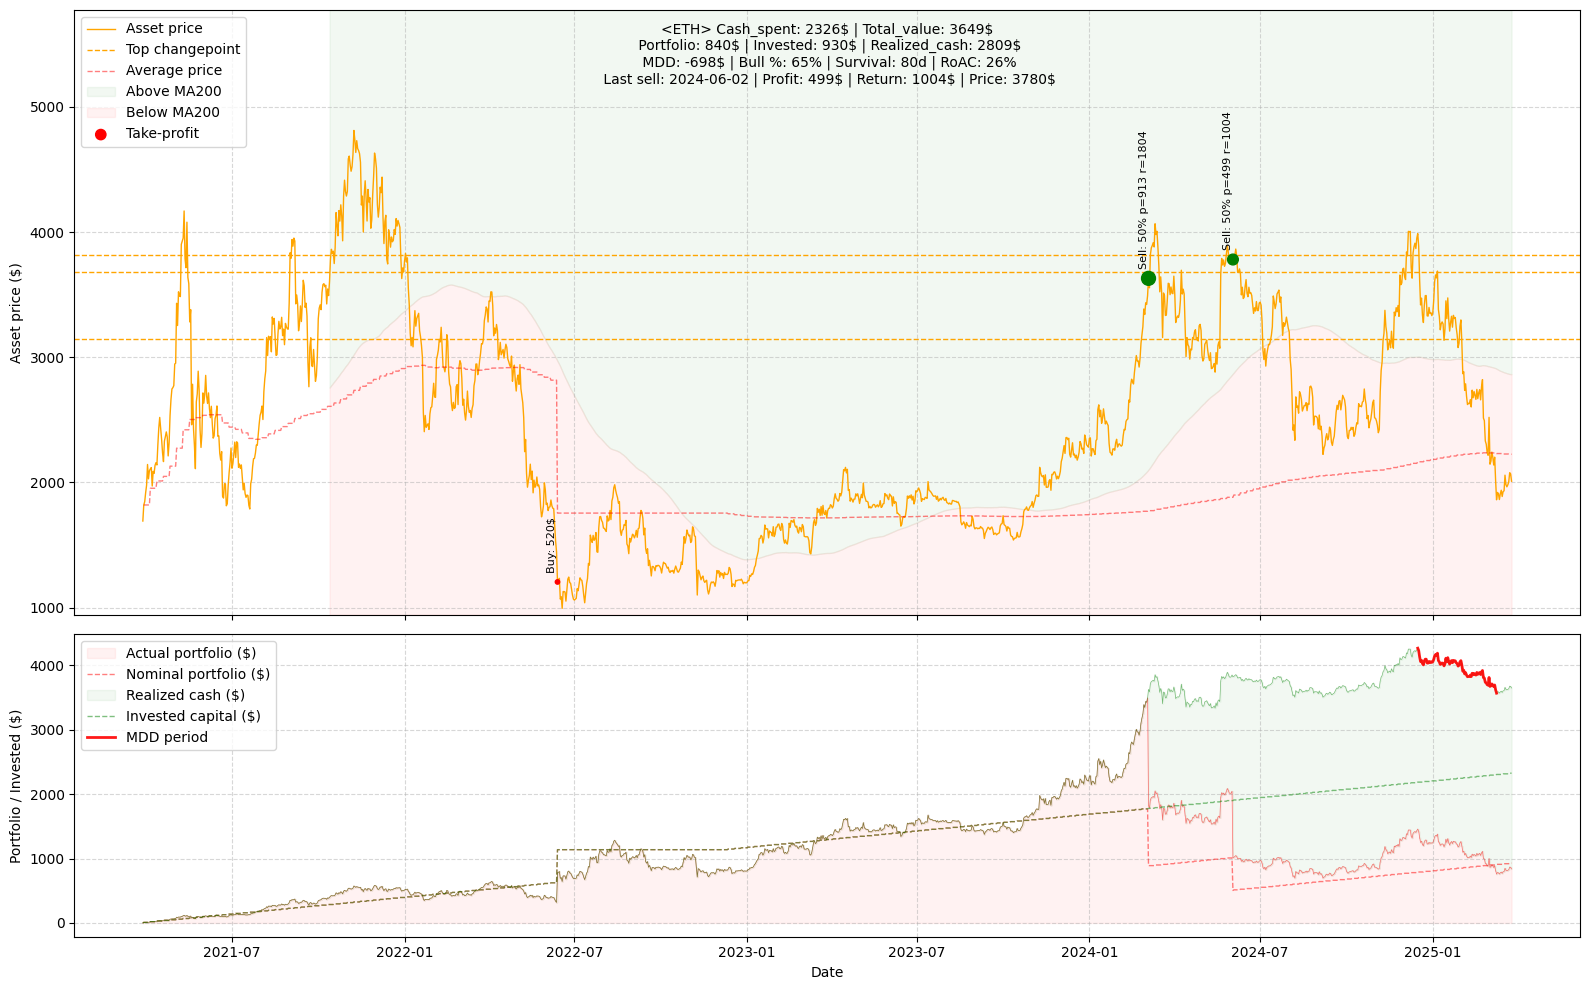

22:49:44 - cmdstanpy - INFO - Chain [1] start processing
22:49:45 - cmdstanpy - INFO - Chain [1] done processing


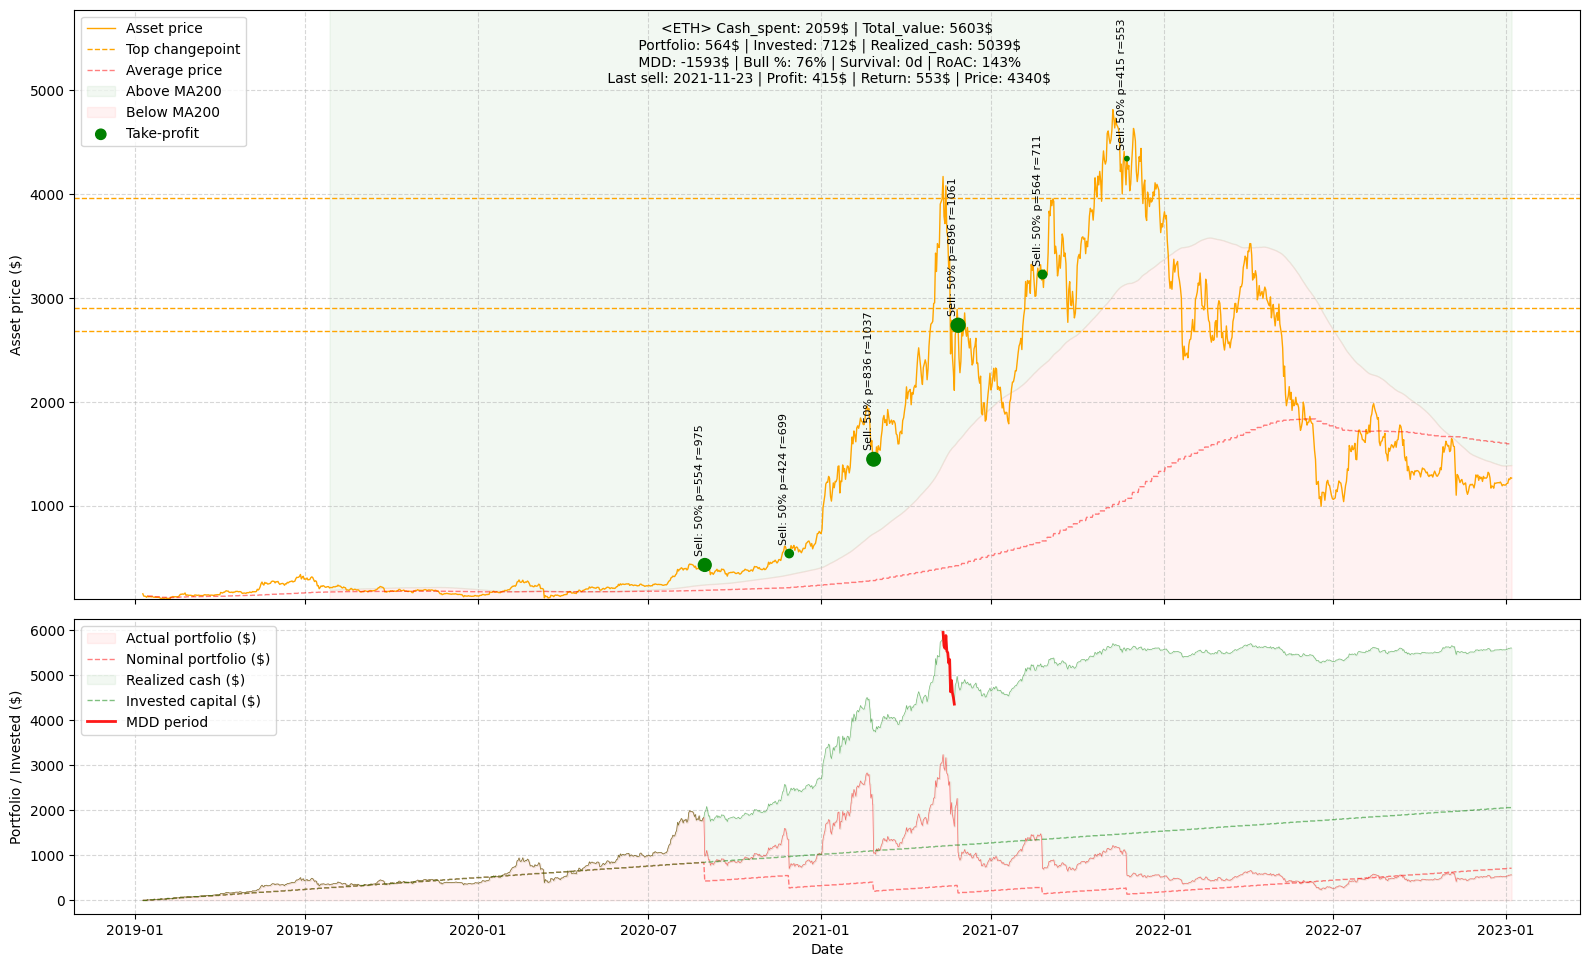

22:49:45 - cmdstanpy - INFO - Chain [1] start processing
22:49:45 - cmdstanpy - INFO - Chain [1] done processing


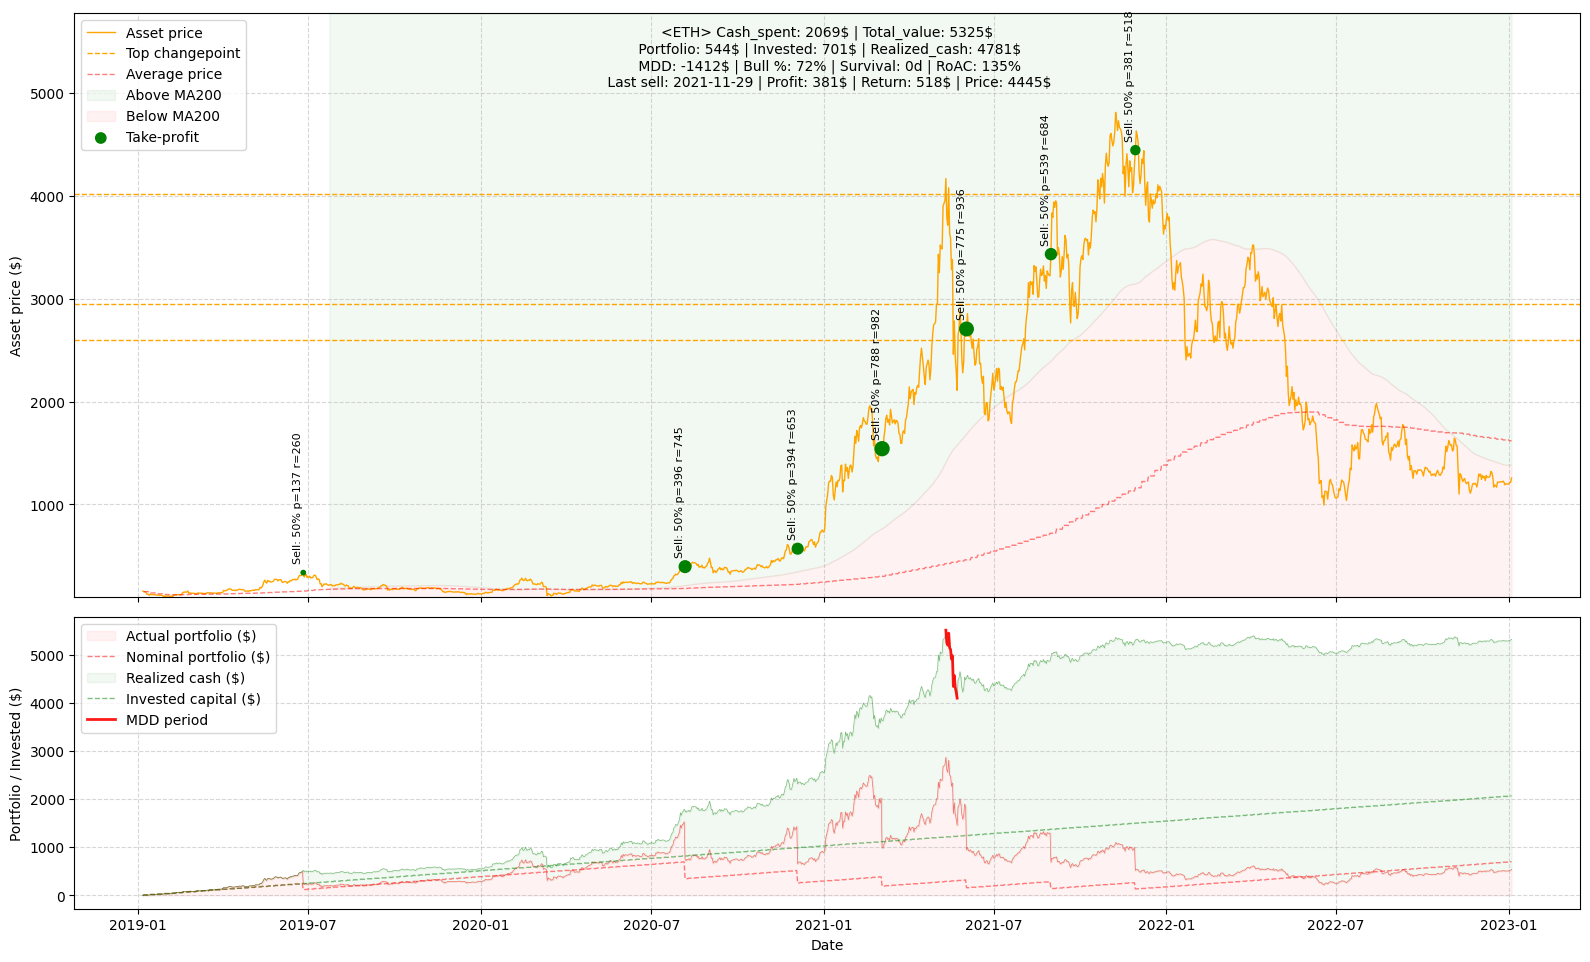

22:49:45 - cmdstanpy - INFO - Chain [1] start processing
22:49:46 - cmdstanpy - INFO - Chain [1] done processing


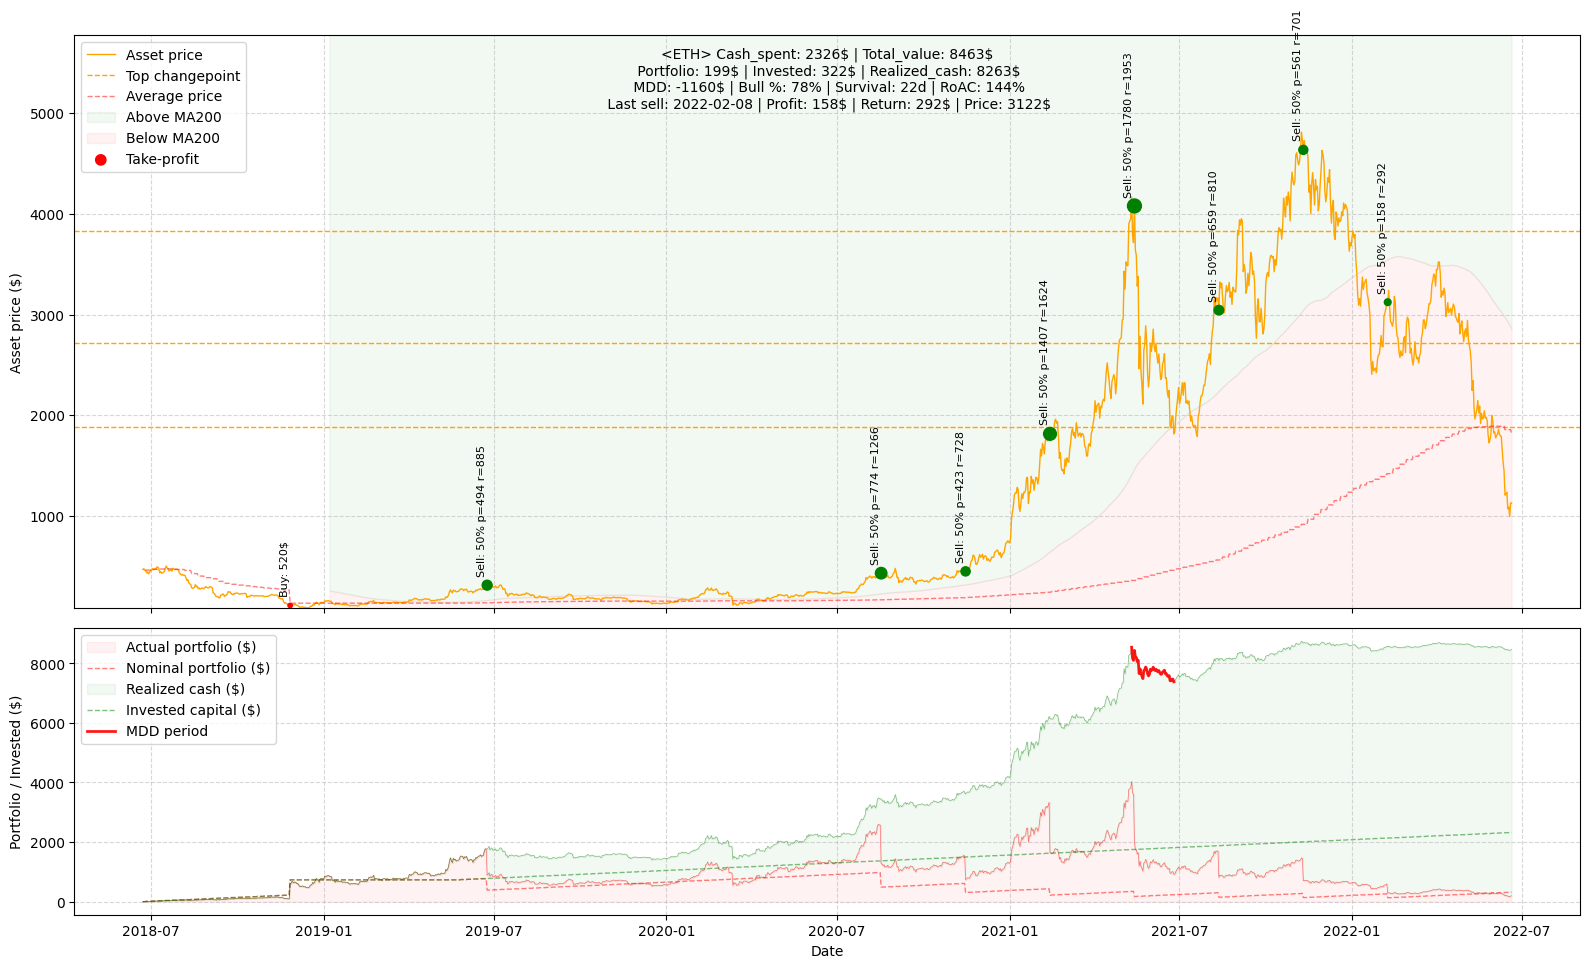

22:49:46 - cmdstanpy - INFO - Chain [1] start processing
22:49:46 - cmdstanpy - INFO - Chain [1] done processing


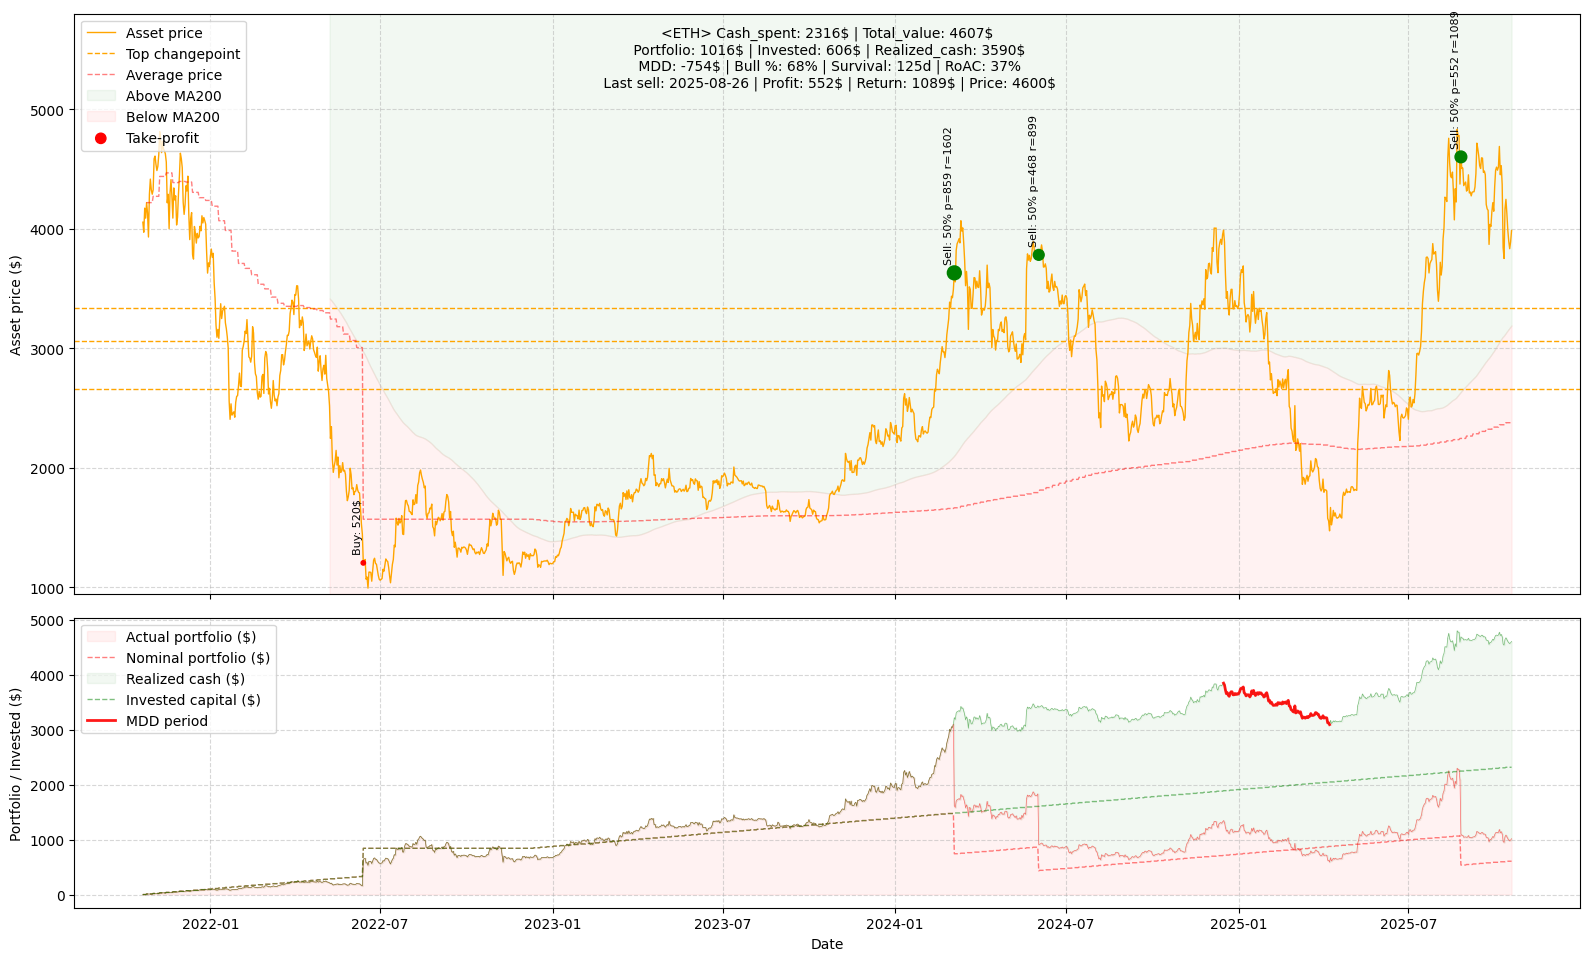

22:49:47 - cmdstanpy - INFO - Chain [1] start processing
22:49:47 - cmdstanpy - INFO - Chain [1] done processing


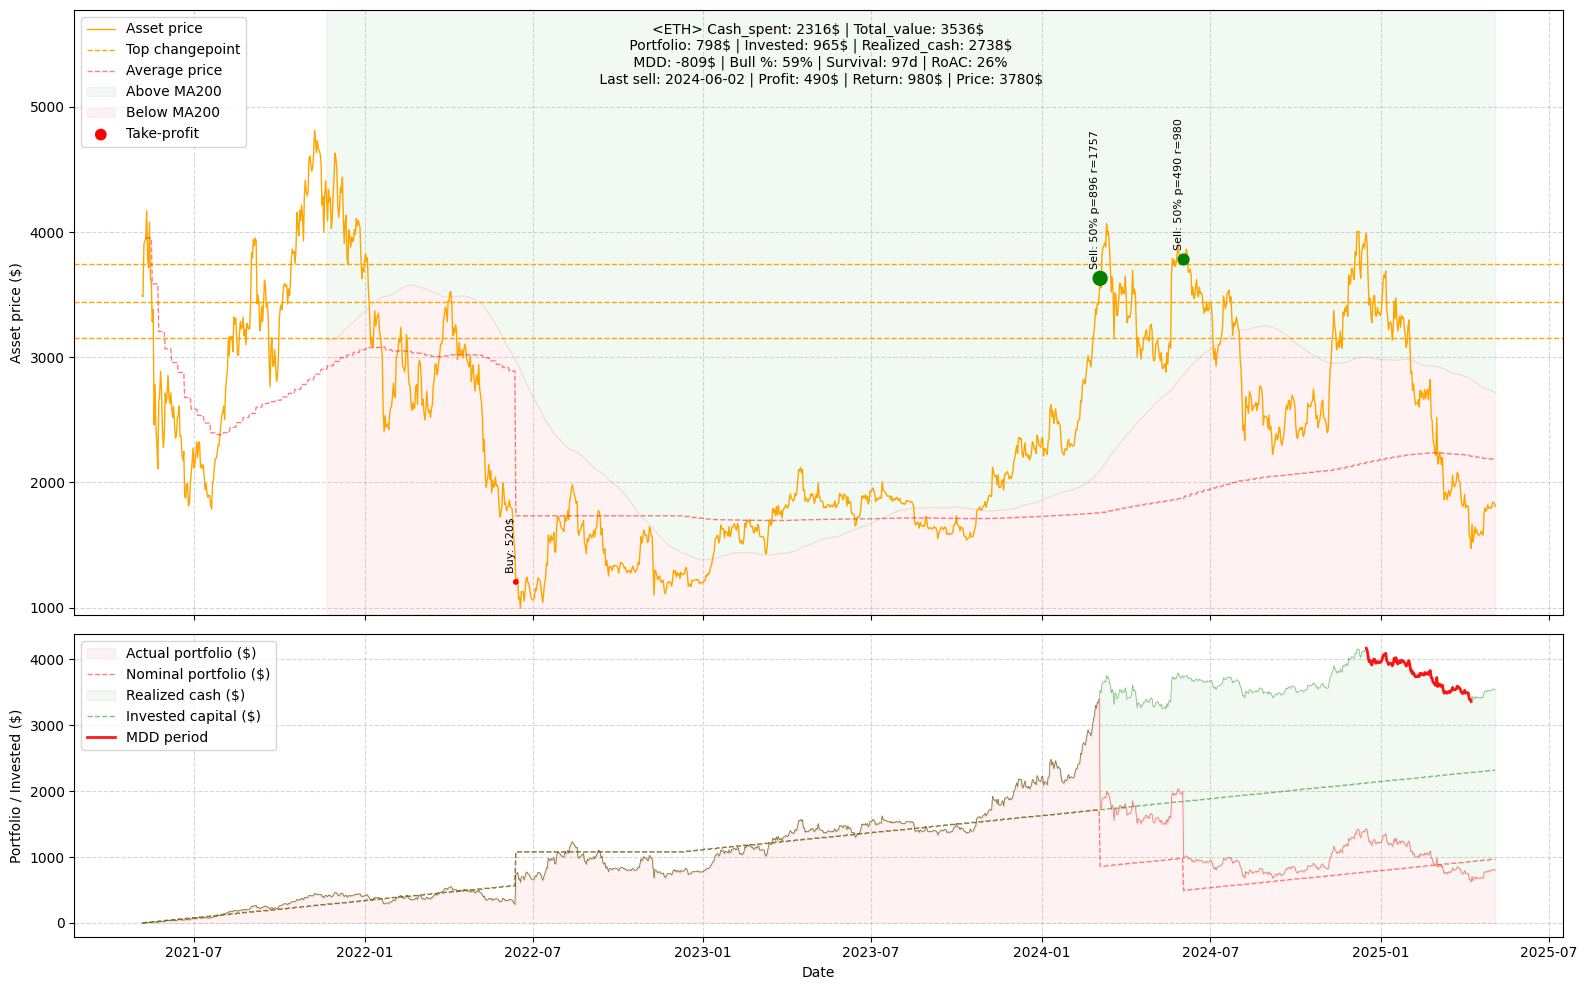

22:49:47 - cmdstanpy - INFO - Chain [1] start processing
22:49:47 - cmdstanpy - INFO - Chain [1] done processing


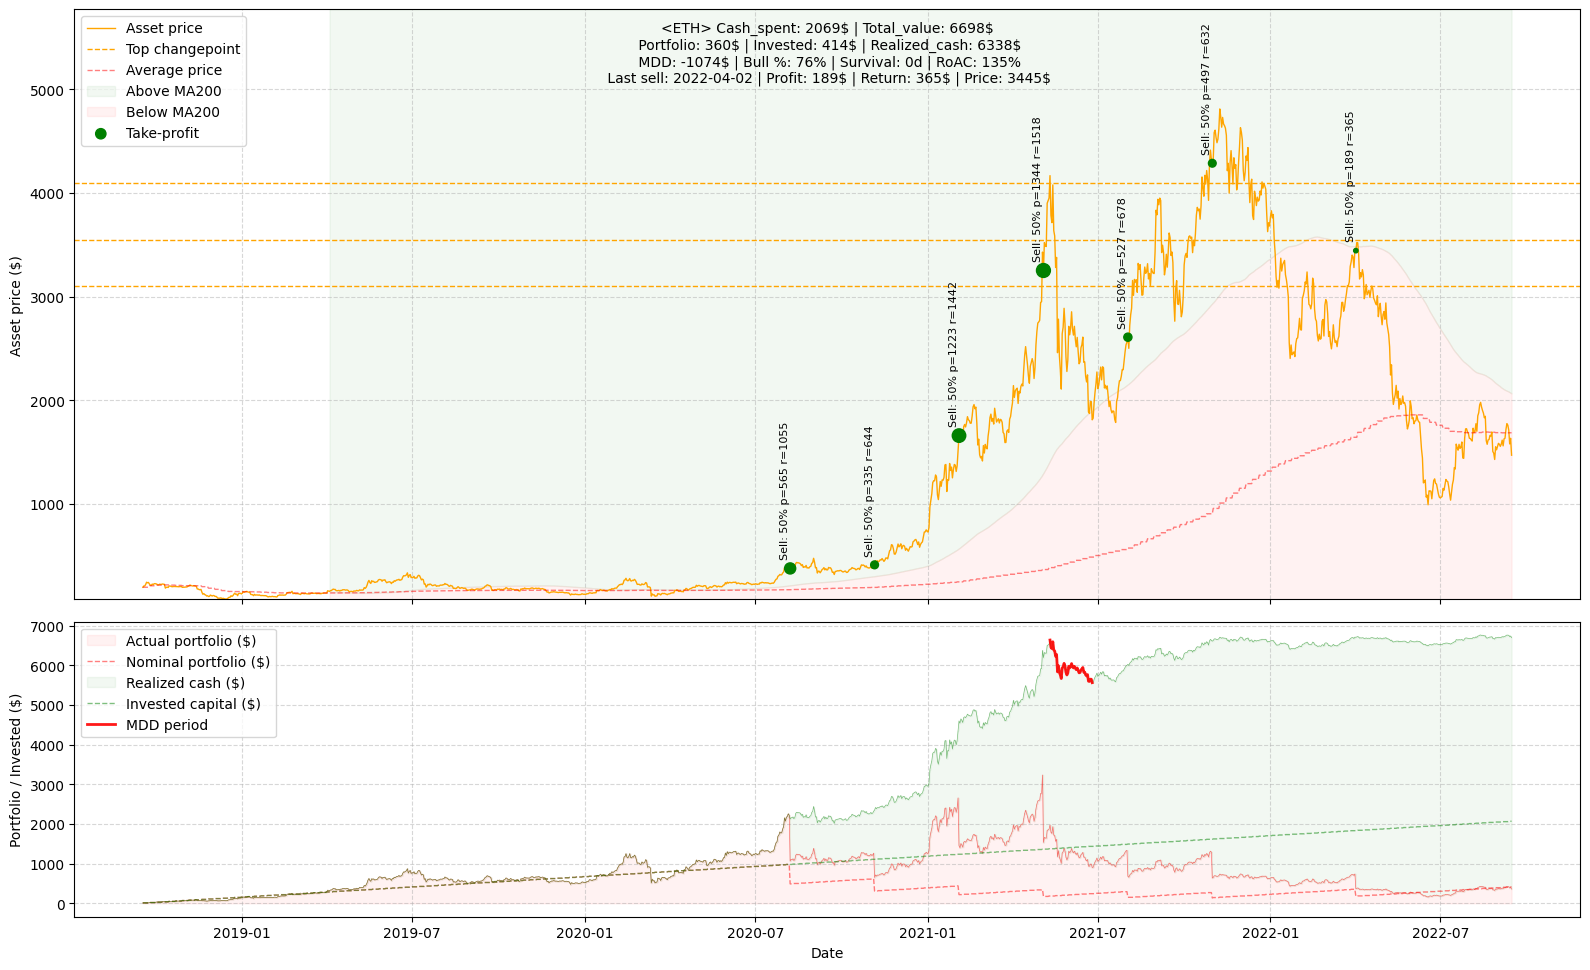

22:49:48 - cmdstanpy - INFO - Chain [1] start processing
22:49:48 - cmdstanpy - INFO - Chain [1] done processing


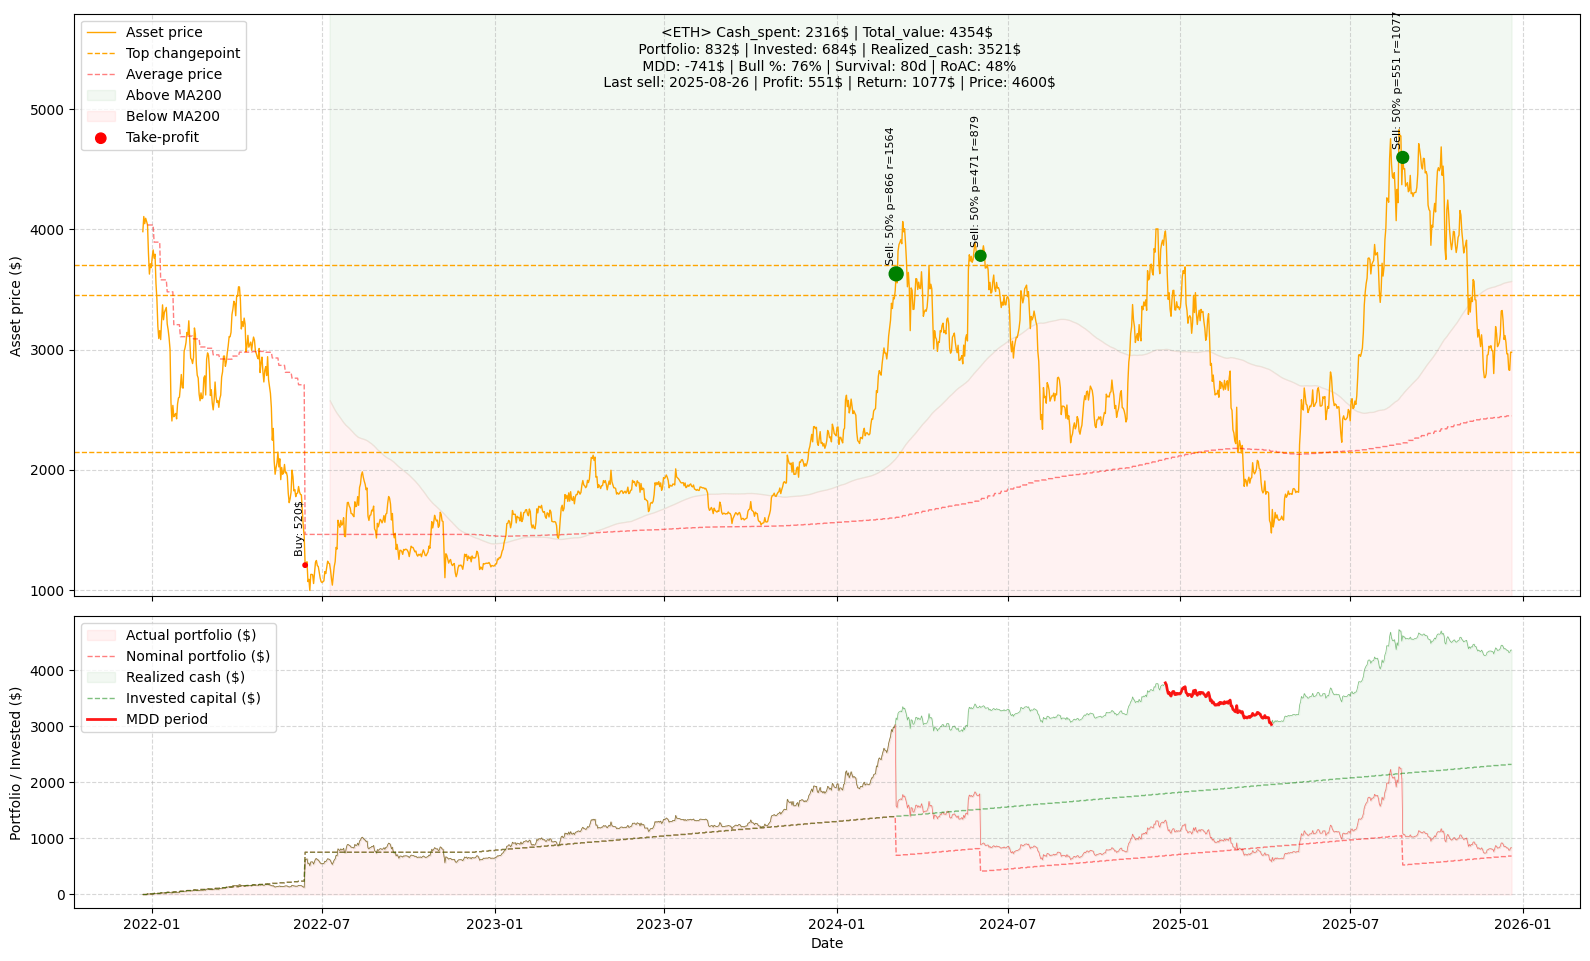

,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,MDD,Survival,RoAC,Period,Start,End
0,ETH,2326,2692,1299,1012,3991,63,-798,93.833333,30,1,2021-06-12,2025-06-10
1,ETH,2316,4785,989,474,5775,86,-583,0.000000,120,2,2020-06-18,2024-06-16
2,ETH,2326,2809,840,930,3649,65,-698,80.000000,26,3,2021-03-28,2025-03-26
3,ETH,2059,5039,564,712,5603,76,-1593,0.000000,143,4,2019-01-09,2023-01-07
4,ETH,2069,4781,544,701,5325,72,-1412,0.000000,135,5,2019-01-06,2023-01-04
5,ETH,2326,8263,199,322,8463,78,-1160,22.000000,144,6,2018-06-22,2022-06-20
6,ETH,2316,3590,1016,606,4607,68,-754,125.000000,37,7,2021-10-21,2025-10-19
7,ETH,2316,2738,798,965,3536,59,-809,97.500000,26,8,2021-05-06,2025-05-04
8,ETH,2069,6338,360,414,6698,76,-1074,0.000000,135,9,2018-09-17,2022-09-15
9,ETH,2316,3521,832,684,4354,76,-741,79.500000,48,10,2021-12-22,2025-12-20


In [8]:
all_metrics = []
last_result = None
last_metrics = None

for p in periods:
    period_prices = p["prices"]

    try:
        bt = BacktestDCA(
        target=STOCK,
        prices=period_prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {STOCK} on period {p['period_id']}: {e}")
        continue

    metrics = metrics.copy()
    metrics["Period"] = p["period_id"]
    metrics["Start"] = p["start"]
    metrics["End"] = p["end"]
    all_metrics.append(metrics)

    last_result = result
    last_metrics = metrics

summary = pd.DataFrame(all_metrics)
summary

In [9]:
last_result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2021-12-22,3982.099609,0.000000,0.0000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2021-12-23,4108.015625,0.000000,0.0000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2021-12-24,4047.982910,0.000000,0.0000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2021-12-25,4093.281006,0.000000,0.0000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2021-12-26,4067.328125,0.000000,0.0000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
...,...,...,...,...,...,...,...,...,...,...,...
2025-12-16,2964.180908,0.279553,684.3375,2316.6,0.0,0.0,3521.667843,,828.646092,2447.969251,4350.313934
2025-12-17,2831.403564,0.279553,684.3375,2316.6,0.0,0.0,3521.667843,,791.527768,2447.969251,4313.195610
2025-12-18,2827.069092,0.279553,684.3375,2316.6,0.0,0.0,3521.667843,,790.316052,2447.969251,4311.983895


In [10]:
last_metrics

{'Target': 'ETH',
 'Cash_spent': 2316,
 'Realized_cash': 3521,
 'Portfolio': 832,
 'Invested': 684,
 'Total_value': 4354,
 'Bull_history': 76,
 'MDD': -741,
 'Survival': 79.50000000000001,
 'RoAC': 48,
 'Period': 10,
 'Start': Timestamp('2021-12-22 00:00:00'),
 'End': Timestamp('2025-12-20 00:00:00')}